In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm_sep as clm
from models import hgm_sep as hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

# functions

In [3]:
def train_numerical_model(model, splits, B_ll, N_res, N_man=None, hyperparameters=None):
	is_hgm = model.get_type()

	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 2000,
			'max_patience': 2000 / 4,
			'learning_rate': 1E-2,
			'w1_reg_lambda': 0.0,
			'w2_reg_lambda': 0,
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	reg_lambdas = hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']
	#endregion ===========================================================================

	n_neurons = N_res.shape[1]
	if is_hgm: n_dimensions = N_man.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =============================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mpe_losses_per_split = list()
	mpe_losses_tr_per_split = list()
	__grads_per_split = list()
	for s_id, (train, test) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		B_ll_train, B_ll_test = jnp.array(B_ll[train]), jnp.array(B_ll[test])
		if is_hgm: N_man_train, N_man_test = jnp.array(N_man[train]), jnp.array(N_man[test])
		N_res_train, N_res_test = jnp.array(N_res[train]), jnp.array(N_res[test])

		if is_hgm:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons))

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(
		# 	init_value=learning_rate,
		# 	decay_steps=max_epochs,
		# 	alpha=1E-2
		# ))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, B_ll_test, N_man_test, N_res_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_test, N_man_test, N_res_test).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()]
		else:
			losses = [model.loss_fn(params, B_ll_test, N_res_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_test, N_res_test).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_res_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mpe_loss = sys.float_info.max
		best_mpe_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_man_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_test, N_man_test, N_res_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_test, N_man_test, N_res_test).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_test, N_res_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_test, N_res_test).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_res_train).item()
			__grads.append(__grad)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mpe_loss = mpe_loss
					best_mpe_loss_tr = mpe_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]
						mpe_losses_tr = mpe_losses_tr + [best_mpe_loss_tr for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses.append(loss)
			losses_tr.append(loss_tr)
			mpe_losses.append(mpe_loss)
			mpe_losses_tr.append(mpe_loss_tr)

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mpe_losses_per_split.append(mpe_losses)
		mpe_losses_tr_per_split.append(mpe_losses_tr)

		__grads_per_split.append(__grads)

		print(f'Split {s_id} completed. ', end='')

		# predicting and scoring ========================================================================
		if is_hgm:
			score_per_neuron = model.score_fn(params, B_ll_test, N_man_test, N_res_test)
		else:
			score_per_neuron = model.score_fn(params, B_ll_test, N_res_test)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# ===========================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mpe_losses_per_split), np.array(mpe_losses_tr_per_split), __grads_per_split

In [4]:
def train_numerical_models(model, filenames, discrete_states, eigenworms, traces_residual, neural_modes=None):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mpe_losses = list()
	models_mpe_losses_tr = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'\n{i + 1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mpe_losses_per_split, mpe_losses_tr_per_split,
		 __grads_per_split) = train_numerical_model(model, splits,
													eigenworms[i].values,
													traces_residual[i].values,
													neural_modes[i].values if neural_modes is not None else None)

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mpe_losses.append(mpe_losses_per_split)
		models_mpe_losses_tr.append(mpe_losses_tr_per_split)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mpe_losses, models_mpe_losses_tr, __models_grads

In [5]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [6]:
# read_ids = [0, 4, 5, 6, 27, 30, 31, 32, 33]
read_ids = [4]
plot_id = 4

# dims = 2
dims_generation = 2
weights = (0.5, 2.)

# selection_n = ['DB01', 'VB02', 'RMDDR', 'RMDDL', 'SMDDR', 'SMDVR']  # high c portion for worm 33
# selection_n = ['VB02', 'SMDDR', 'SMDDL', 'RMDDR', 'RMDDL', 'SMDVR']  # high c portion for worm 24
# selection_n = ['DD01', 'VB02', 'SMDDR', 'DB01', 'RMDDR', 'AVAR', 'AVAL']
selection_n = ['VB02', 'RMDDR', 'AVAR', 'AVAL']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


artificial = False

# read & get residuals

In [7]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path, read_ids)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

discrete_states = [ds[selection_bhl] for ds in discrete_states]


traces_residual = None

if not artificial:
	(neural_modes, _,
	 traces_manifold, _,
	 cca_loadings_man,
	 vars_expl_man, vars_expl_man_rs) = train_utils.get_manifolds(traces,
																  discrete_states,
																  n_cc=2, n_pc=5)

	traces_residual = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces, traces_manifold)]

	# plot_utils.plot_manifolds(filenames,
	# 						  neural_modes,
	# 						  discrete_states,
	# 						  vars_expl_man, vars_expl_man_rs,
	# 						  n_plots=None, plots_per_row=1)




else:
	filenames_art = list()
	discrete_states_art = discrete_states.copy()
	eigenworms_art = eigenworms.copy()
	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()
	for i in range(len(filenames)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames[i],
														 traces[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)


	neural_modes = neural_modes_art
	traces_residual = traces_residual_art
	traces = traces_art




# traces = [t[selection_n] for t in traces]
# traces_residual = [t[selection_n] for t in traces_residual]

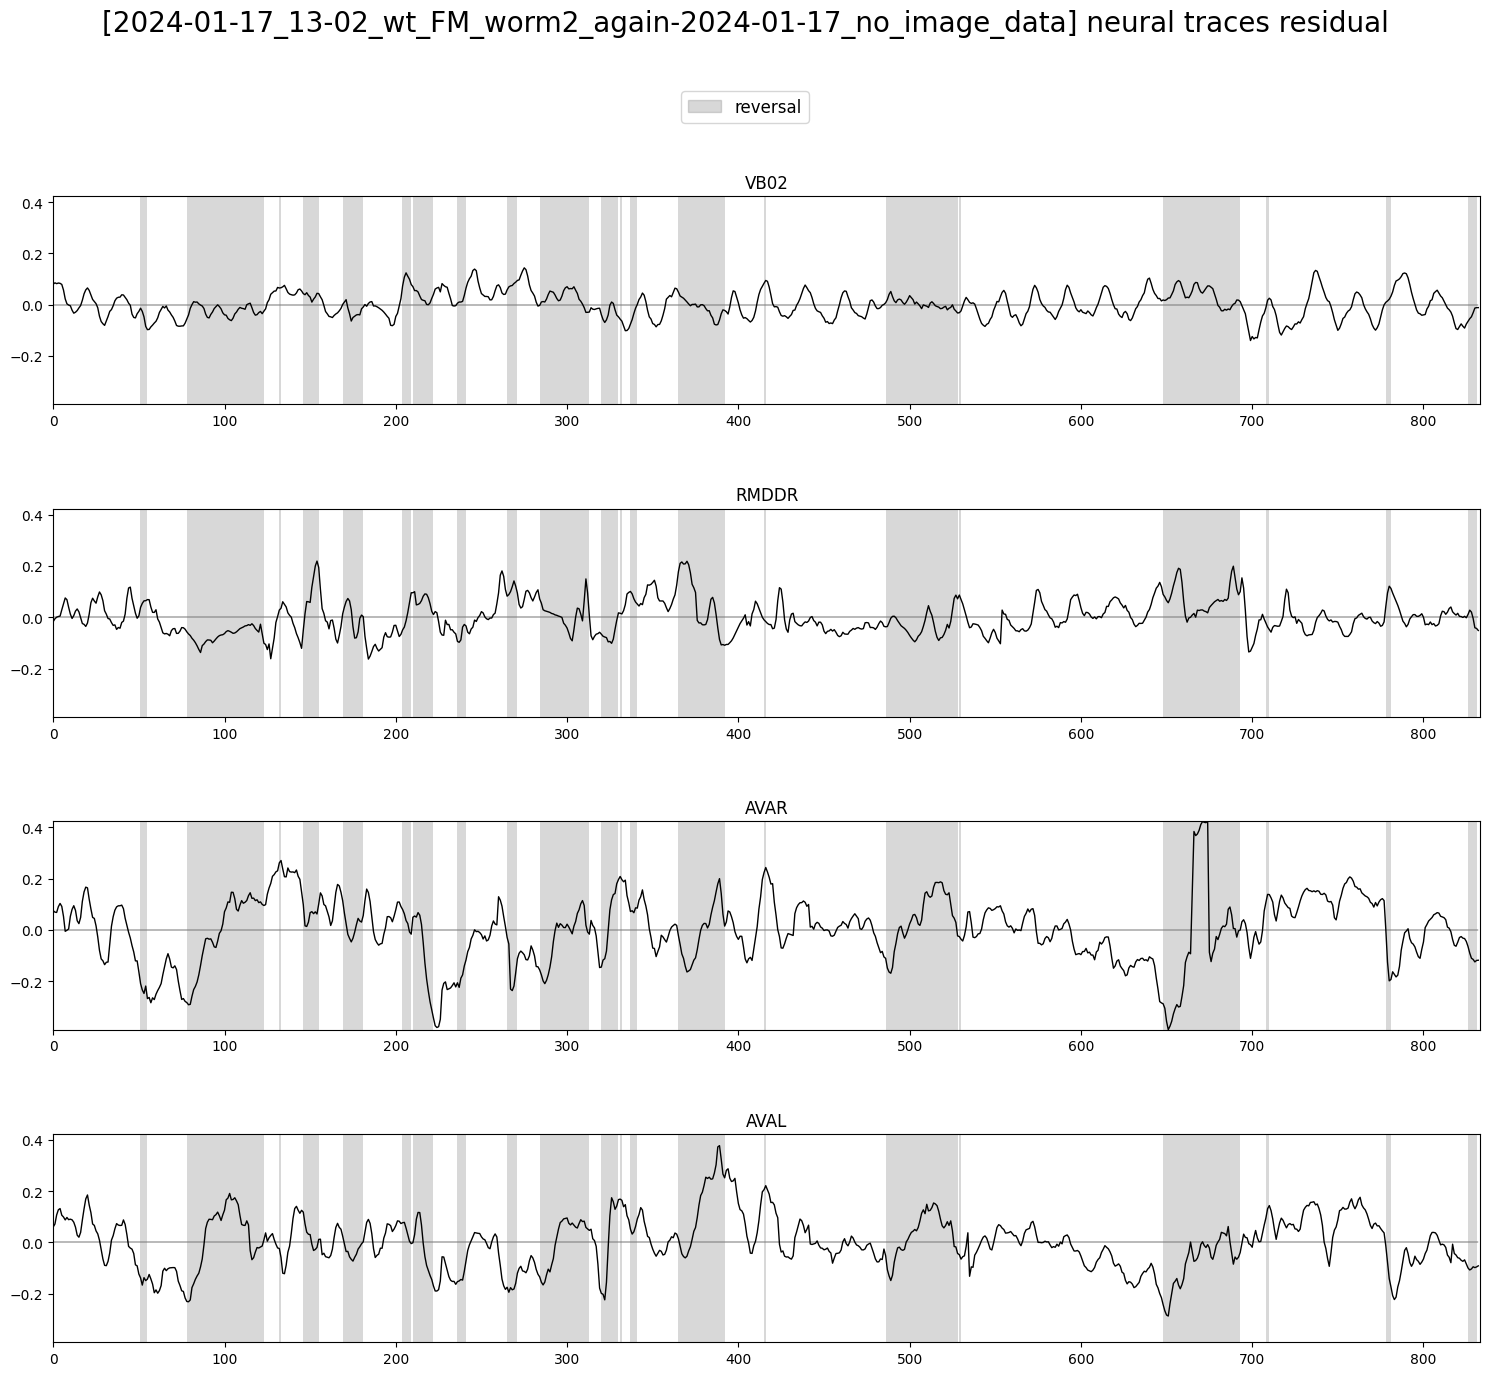

In [8]:
plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}] neural traces residual',
					   discrete_states[file_ids.index(plot_id)]['REV'],
					   traces_residual[file_ids.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

# train

In [9]:
(clm_models_params,
 clm_models_scores,
 clm_models_losses, clm_models_losses_tr,
 clm_models_mpe_losses, clm_models_mpe_losses_tr,
 __clm_models_grads) = train_numerical_models(clm,
											  filenames,
											  discrete_states,
											  eigenworms,
											  traces_residual)


1/1: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1791 epochs: Split 0 completed. Stopped after 1295 epochs: Split 1 completed. Stopped after 1659 epochs: Split 2 completed. Stopped after 1472 epochs: Split 3 completed. Stopped after 1130 epochs: Split 4 completed. 

In [10]:
(hgm_models_params,
 hgm_models_scores,
 hgm_models_losses, hgm_models_losses_tr,
 hgm_models_mpe_losses, hgm_models_mpe_losses_tr,
 __hgm_models_grads) = train_numerical_models(hgm,
											  filenames,
											  discrete_states,
											  eigenworms,
											  traces_residual,
											  neural_modes)


1/1: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1017 epochs: Split 0 completed. Stopped after 1120 epochs: Split 1 completed. Stopped after 1010 epochs: Split 2 completed. Stopped after 1078 epochs: Split 3 completed. Stopped after 1032 epochs: Split 4 completed. 

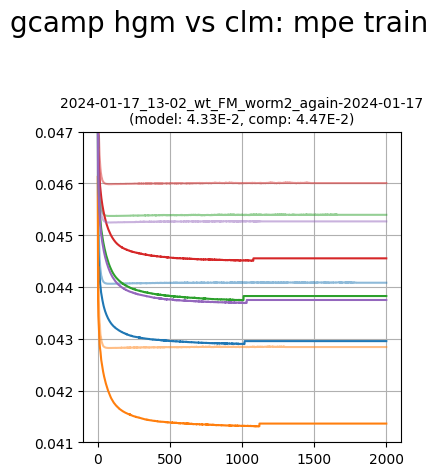

In [11]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: mpe train',
							  filenames,
							  hgm_models_mpe_losses_tr, clm_models_mpe_losses_tr,
							  plots_per_row=4, ylimits=(0.041, 0.047))

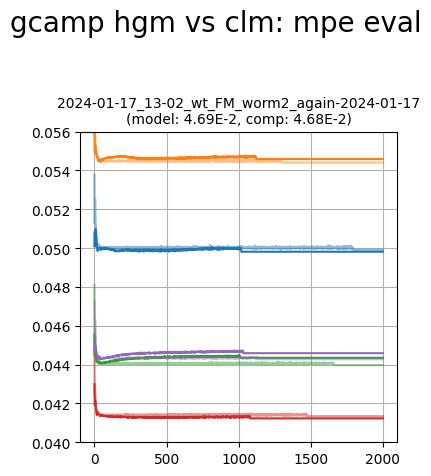

In [12]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: mpe eval',
							  filenames,
							  hgm_models_mpe_losses, clm_models_mpe_losses,
							  plots_per_row=4, ylimits=(0.04, 0.055))

# performance

In [13]:
neuron_scores = assemble(filenames, traces, clm_models_scores, hgm_models_scores)

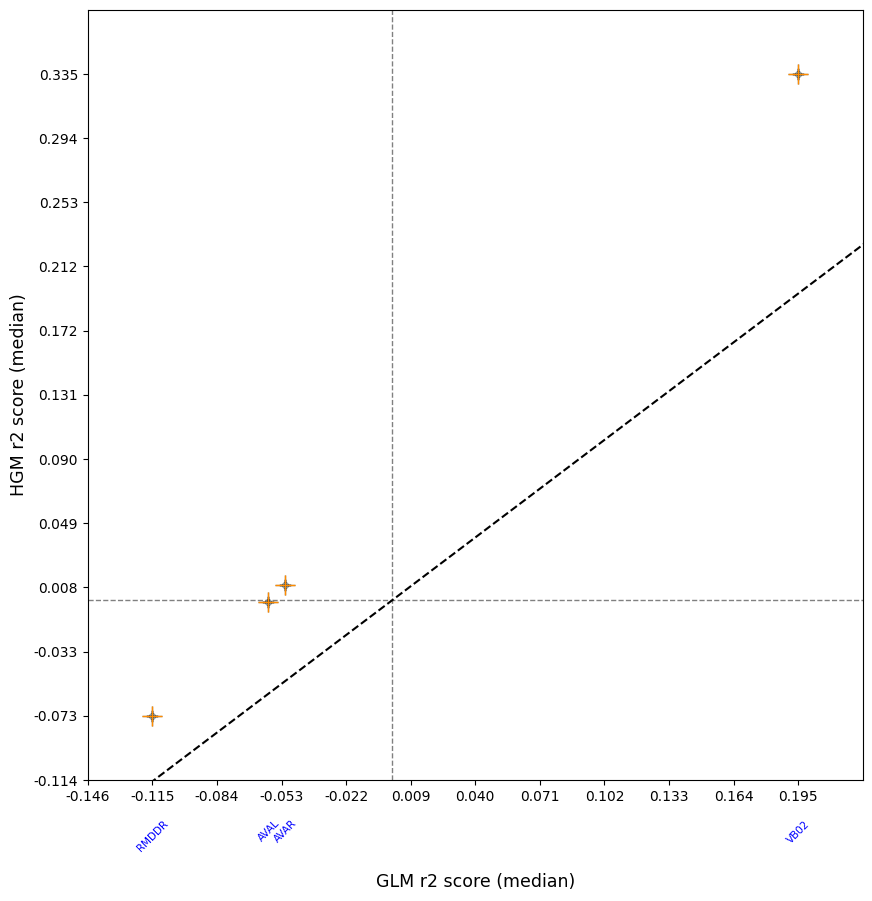

In [14]:
importlib.reload(plot_utils)
plot_utils.plot_performance_plot({key: neuron_scores[key] for key in selection_n}, None,
								 limits=None, content_size=20)

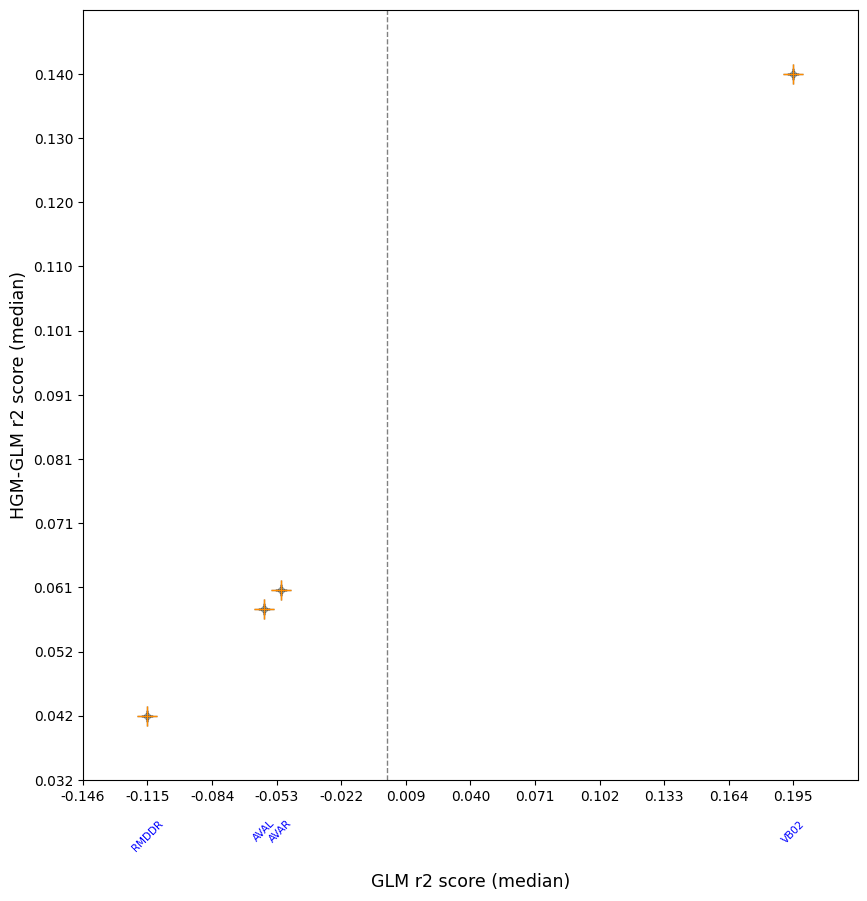

In [15]:
plot_utils.plot_improvement_plot({key: neuron_scores[key] for key in selection_n}, None,
								 limits=None, content_size=20)

# traces

In [16]:
clm_predicted_traces = [[
	pd.DataFrame(data=clm.predict(eigenworms[i].values, params['W']),
				 columns=traces[i].columns) for params in clm_models_params[i]
] for i in range(len(traces))]

hgm_predicted_traces = [[
	pd.DataFrame(data=hgm.predict(eigenworms[i].values, neural_modes[i].values, params['W1'], params['W2']),
				 columns=traces[i].columns) for params in hgm_models_params[i]
] for i in range(len(traces))]

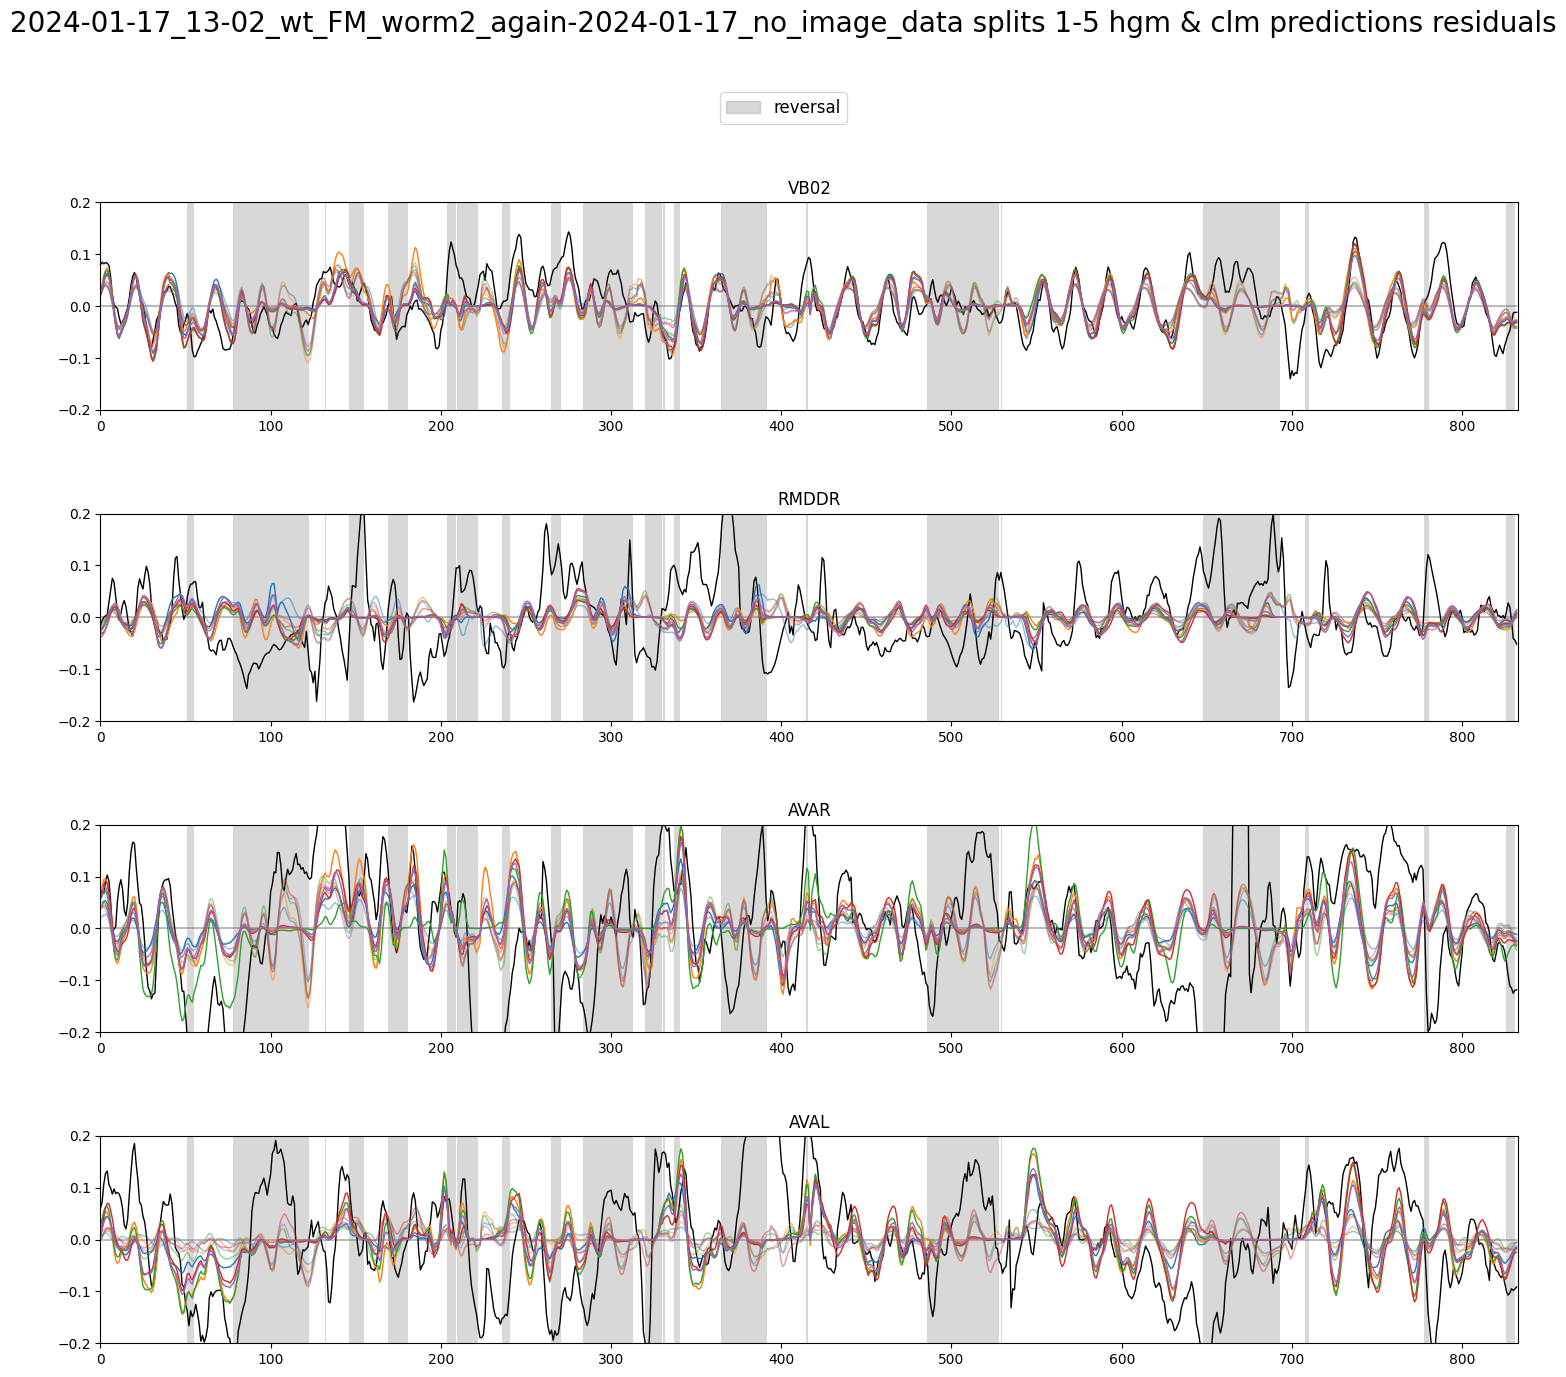

In [17]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames[file_ids.index(plot_id)]} splits {1}-{splits} hgm & clm predictions residuals',
	discrete_states[file_ids.index(plot_id)]['REV'],
	traces_residual[file_ids.index(plot_id)][selection_n],
	[hgm_predicted_traces[file_ids.index(plot_id)][i][selection_n] for i in range(splits)],
	[clm_predicted_traces[file_ids.index(plot_id)][i][selection_n] for i in range(splits)],
	n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.2, 0.2))